## Fuentes

1. **Yazdani, Bidgoli, et al. (2023), MDPI Sustainability** — https://www.mdpi.com/2071-1050/15/23/16476: simulación de embarque en A320, usan p= 0,75 de pasajeros con carry-on, tiempo de acceso al asiento ~Triangular(1.8, 2.4, 3) s, tiempo de respuesta (dejar pasar a otro) ~Triangular(6, 9, 20) s, y tiempo de guardado de equipaje ~Weibull(α=16.0, β=1.7).
2. **de Oliveira et al. (2021), Int. J. of Aerospace Engineering** — https://onlinelibrary.wiley.com/doi/10.1155/2021/8872992: compara boarding/deboarding en aviones de 120 pasajeros cada uno. La configuración "four abreast" (2+2, 30 filas) es la más parecida a la nuestra. Usan tiempos fijos: sentarse 3 s, pararse 3 s, guardar/sacar equipaje 5 s.
3. **Airlines for America (A4A), datos DOT Form 41, 2025** — https://www.airlines.org/dataset/u-s-passenger-carrier-delay-costs/: costo operativo directo de una aeronave parada/en rodaje es US\$98.41 por minuto.
4. **Bureau of Transportation Statistics, 2025** https://www.bts.gov/newsroom/2025-annual-average-domestic-air-fare-decreases-2024: tarifa aérea doméstica promedio en EE.UU. = US\$387 (2025).

De la (1) y la (2) tomamos la *media* de cada tiempo de comportamiento (sentarse, guardar el carry-on, dejar pasar) como valor fijo. Con la (3) y la (4) resolvemos la pregunta de costos del enunciado.

# Trabajo Práctico 1. Aplicaciones Computacionales en Negocios

Integrantes:

Sasha Cattaneo

Martina Cosentino

Facundo Guledjian

Luciano Jacofsky







## Supuestos

| Parámetro | Tipo | Valor | Fuente |
|---|---|---|---|
| Tiene carry-on (por pasajero) | Bernoulli(p), aleatorio | p = 0.75 | Yazdani et al. 2023 (fuente 1) |
| Cruzar una fila sin carry-on | fijo | 3 s | Regla del enunciado |
| Cruzar una fila con carry-on | fijo | 6 s | Regla del enunciado |
| Sentarse (asiento libre) | fijo | 2.4 s | Media de Triangular(1.8, 2.4, 3.0) de la fuente 1 |
| Guardar el carry-on | fijo | 14.0 s | Media de Weibull(α=16, β=1.7) de la fuente 1 (≈14.27 s) |
| Dejar pasar a otro pasajero (pararse + cruzarse + volver a sentarse, todo junto) | fijo | 11.0 s | Media de Triangular(6, 9, 20) de la fuente 1|
| Buffer de 3 s de espacio vacío antes de avanzar | fijo | 3 s | Regla del enunciado|
| Costos operativos por demora de un minuto | fijo | USD 98,41 | Airlines for America (fuente 3)|
| Tarifa aérea doméstica promedio en EE.UU. | fijo | USD 387 | Bureau of Transportation Statistics (fuente 4)|


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

filas = 25
lados = [-2, -1, 1, 2]

avanzar = 3.0
avanzar_carryon = 6.0
espera = 3.0

sentar = 2.4
dejar_pasar = 11.0
guardar_carryon = 14.0

p_carryon = 0.75


costo_minuto = 98.41
tarifa = 387.0

In [ ]:
#### Pasajeros
class Pasajero:
  def __init__(self, fila, lado, carryon):
    self.fila = fila
    self.lado = lado
    self.carryon=carryon
    if self.carryon==True:
      self.velocidad=avanzar_carryon
    else:
      self.velocidad=avanzar

    self.sentado = False
    self.tiempo_restante_accion = 0 #temporizador para la accion
    self.estado ='en_cola'


In [ ]:
#modelado del avion
class Avion:
  def __init__(self, proba):
    self.filas = filas
    self.pasajeros = self._crear_pasajeros(proba)
    self.mapa = {}
    for p in self.pasajeros:
      self.mapa[(p.fila, p.lado)] = p

  def _crear_pasajeros(self, proba):
      pasajeros = []
      for fila in range(filas):
          for lado in [-2, -1, 1, 2]:
              carryon = random.random() < proba
              pasajeros.append(Pasajero(fila, lado, carryon))
      return pasajeros




In [ ]:
def Backtofront(avion):
  inicio=96
  fin=100
  fila=[]
  while inicio>=0:
    temp=avion.pasajeros[inicio:fin]
    random.shuffle(temp)
    for pasajero in temp:
      fila.append(pasajero)
    inicio-=4
    fin-=4
  return fila

In [ ]:
def orden_random(avion):
    pasajeros_copia = list(avion.pasajeros)
    random.shuffle(pasajeros_copia)
    return pasajeros_copia

In [ ]:
def orden_wilma(avion):
    pasajeros_ventana = []
    pasajeros_pasillo = []

    for pasajero in avion.pasajeros:
        if pasajero.lado == -2 or pasajero.lado == 2:
            pasajeros_ventana.append(pasajero)
        else:
            pasajeros_pasillo.append(pasajero)

    random.shuffle(pasajeros_ventana)
    random.shuffle(pasajeros_pasillo)

    return pasajeros_ventana + pasajeros_pasillo

In [ ]:
def orden_steffen(avion):
    orden = []
    # primero las ventanas (lado +-2) y después el pasillo (lado +-1)
    for grupo_lados in [(-2, 2), (-1, 1)]:
        # primero filas pares de atras para adelante, después impares
        for paridad in [0, 1]:
            for lado in grupo_lados: # Según el lado en ventana (-2 o 2) y después en pasillo (-1 O 1), recorro y asigno el orden en función de la paridad de las filas
                for f in range(avion.filas - 1, -1, -1): # recorro de atras para adelante de la fila n a la 0 inclusive
                    if f % 2 == paridad: # primero paridad = 0 (filas pares), después paridad = 1 (filas impares)
                        orden.append(avion.mapa[(f, lado)])
    return orden

In [ ]:
def sentarse(pasajero, avion):
    tiempo = sentar
    if pasajero.carryon:
        tiempo += guardar_carryon
    vecino_izq = avion.mapa[(pasajero.fila, -1)]
    vecino_der = avion.mapa[(pasajero.fila, 1)]

    if pasajero.lado == -2 and vecino_izq.sentado:
        tiempo+=dejar_pasar
    if pasajero.lado == 2 and vecino_der.sentado:
        tiempo+=dejar_pasar

    return tiempo

In [ ]:
def simulacion(avion, fila):
    fila = list(fila)
    total_pasajeros = len(fila)
    pasillo = [None] * avion.filas # para ver si esa fila del pasillo esta ocupada
    tiempo_libre_pasillo=[0] * avion.filas  #esto nos sirve para el chequeo de 3 segundos:)
    segundos=0
    pasajeros_sentados=0


    #mientras no se hayan sentado todos
    while pasajeros_sentados < total_pasajeros:
        segundos += 1
        for f in range(avion.filas):
          if pasillo[f] == None:
            tiempo_libre_pasillo[f]+=1
          else:
            tiempo_libre_pasillo[f]=0

        for fila_actual in range(filas - 1, -1, -1):
            pasajero = pasillo[fila_actual]
            if pasajero is None:
                continue

            # Descontar 1 segundo del timer
            pasajero.tiempo_restante_accion -= 1

            if pasajero.tiempo_restante_accion > 0:
                continue

            if fila_actual == pasajero.fila:
                if pasajero.estado == 'caminando':
                    # Acaba de llegar: calcular cuánto tarda en sentarse
                    pasajero.tiempo_restante_accion  = sentarse(pasajero, avion)
                    pasajero.estado = 'sentandose'

                elif pasajero.estado == 'sentandose':
                    pasajero.sentado = True
                    pasajero.estado ='sentado'
                    pasillo[fila_actual]= None
                    pasajeros_sentados+= 1

            else:
                siguiente = fila_actual + 1
                if siguiente < filas and  tiempo_libre_pasillo[siguiente] >= espera:
                    pasillo[siguiente] = pasajero
                    pasillo[fila_actual] = None
                    pasajero.tiempo_restante_accion = pasajero.velocidad

        if pasillo[0] is None and tiempo_libre_pasillo[0] >= espera and len(fila) > 0:
            nuevo = fila.pop(0)
            pasillo[0] = nuevo
            tiempo_libre_pasillo[0]  = 0
            nuevo.tiempo_restante_accion = nuevo.velocidad
            nuevo.estado='caminando'

    return segundos


## Monte Carlo: media, desvío y error de estimación

Corremos 3000 simulaciones independientes por política y analizamos media, desvío y error estandar.

In [ ]:
def run_simulations(funcion, proba, num_simulations=3000):
    tiempos = []
    for i in range(num_simulations):
        avion = Avion(proba)
        orden = funcion(avion)
        tiempo = simulacion(avion, orden)
        tiempos.append(tiempo)

    media = np.mean(tiempos)
    desvio = np.std(tiempos, ddof=1)
    error_estandar = desvio / np.sqrt(len(tiempos))

    return tiempos, media, desvio, error_estandar

resultados = {}

# Back-to-Front
print("Corriendo Back-to-Front 3000 simulaciones...")
tiempos_btf, media_btf, desvio_btf, error_estandar_btf = run_simulations(Backtofront, p_carryon)
resultados['Back-to-Front'] = {
    'tiempos': tiempos_btf,
    'media': media_btf,
    'desvio': desvio_btf,
    'error_estandar': error_estandar_btf
}

# Random
print("Corriendo Random 3000 simulaciones...")
tiempos_random, media_random, desvio_random, error_estandar_random = run_simulations(orden_random, p_carryon)
resultados['Random'] = {
    'tiempos': tiempos_random,
    'media': media_random,
    'desvio': desvio_random,
    'error_estandar': error_estandar_random
}

# Wilma
print("Corriendo Wilma 3000 simulaciones...")
tiempos_wilma, media_wilma, desvio_wilma, error_estandar_wilma = run_simulations(orden_wilma, p_carryon)
resultados['Wilma'] = {
    'tiempos': tiempos_wilma,
    'media': media_wilma,
    'desvio': desvio_wilma,
    'error_estandar': error_estandar_wilma
}

# Steffen
print("Corriendo Steffen 3000 simulaciones...")
tiempos_steffen, media_steffen, desvio_steffen, error_estandar_steffen = run_simulations(orden_steffen, p_carryon)
resultados['Steffen'] = {
    'tiempos': tiempos_steffen,
    'media': media_steffen,
    'desvio': desvio_steffen,
    'error_estandar': error_estandar_steffen
}

print("Terminado!")

Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulaciones...
Terminado!


### Resultados de la simulación

In [ ]:
import pandas as pd
summary_data = []
for politica, data in resultados.items():
    summary_data.append({
        'Politica(minutos)': politica,
        'Media(minutos)': data['media']/60,
        'Desvío Estándar(minutos)': data['desvio']/60,
        'Error Estándar(minutos)': data['error_estandar']/60
    })

df_summary = pd.DataFrame(summary_data)
display(df_summary)


,Politica(minutos),Media(minutos),Desvío Estándar(minutos),Error Estándar(minutos)
0,Back-to-Front,33.542067,1.183712,0.021612
1,Random,23.952672,0.977028,0.017838
2,Wilma,22.488194,0.820308,0.014977
3,Steffen,17.499556,0.233304,0.004260


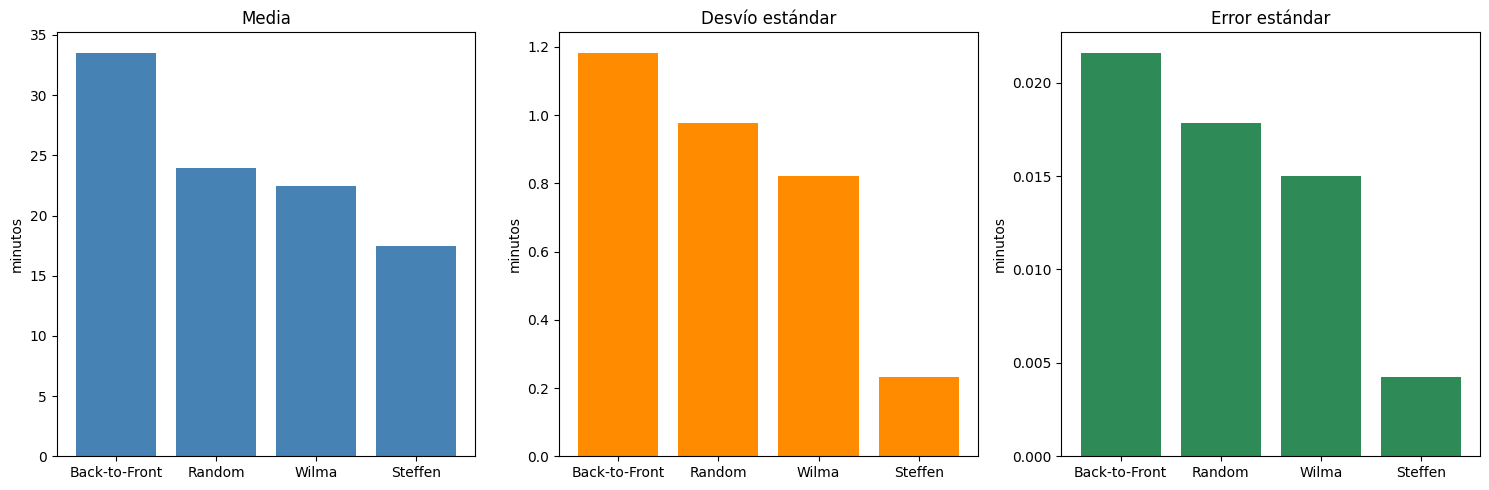

In [ ]:
politicas_nombres = list(resultados.keys())
medias = [resultados[p]["media"]/60 for p in politicas_nombres]
desvios = [resultados[p]["desvio"]/60 for p in politicas_nombres]
errores = [resultados[p]["error_estandar"]/60 for p in politicas_nombres]

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))

ejes[0].bar(politicas_nombres, medias, color="steelblue")
ejes[0].set_title("Media")
ejes[0].set_ylabel("minutos")

ejes[1].bar(politicas_nombres, desvios, color="darkorange")
ejes[1].set_title("Desvío estándar")
ejes[1].set_ylabel("minutos")

ejes[2].bar(politicas_nombres, errores, color="seagreen")
ejes[2].set_title("Error estándar")
ejes[2].set_ylabel("minutos")

plt.tight_layout()
plt.show()

## Comparación con los papers

El orden que da la simulación (Steffen más rápido, después Wilma, después Random, y Back-to-Front el más lento) coincide con lo que encuentran Yazdani et al. 2023 (fuente 1), que comparan las mismas políticas y también encuentran a Steffen como la más rápida y a Back-to-Front entre las peores.

In [ ]:

###diferentes proba de carry-on
resultadoscarry = {}
proba=np.linspace(0, 1, 6, dtype=float)
for p in proba:
  # Back-to-Front
  print("Corriendo Back-to-Front 3000 simulaciones...")
  tiempos_btf, media_btf, desvio_btf, error_estandar_btf = run_simulations(Backtofront, p)
  resultadoscarry[f'Back-to-Front proba={p}'] = {
      'tiempos': tiempos_btf,
      'media(minutos)': media_btf/60,
      'desvio(minutos)': desvio_btf/60,
      'error_estandar(minutos)': error_estandar_btf/60
  }

  # Random
  print("Corriendo Random 3000 simulaciones...")
  tiempos_random, media_random, desvio_random, error_estandar_random = run_simulations(orden_random, p)
  resultadoscarry[f'Random proba={p}'] = {
      'tiempos': tiempos_random,
      'media(minutos)': media_random/60,
      'desvio(minutos)': desvio_random/60,
      'error_estandar(minutos)': error_estandar_random/60
  }

  # Wilma
  print("Corriendo Wilma 3000 simulaciones...")
  tiempos_wilma, media_wilma, desvio_wilma, error_estandar_wilma = run_simulations(orden_wilma, p)
  resultadoscarry[f'Wilma proba={p}'] = {
      'tiempos': tiempos_wilma,
      'media(minutos)': media_wilma/60,
      'desvio(minutos)': desvio_wilma/60,
      'error_estandar(minutos)': error_estandar_wilma/60
  }

  # Steffen
  print("Corriendo Steffen 3000 simulaciones...")
  tiempos_steffen, media_steffen, desvio_steffen, error_estandar_steffen = run_simulations(orden_steffen, p)
  resultadoscarry[f'Steffen proba={p}'] = {
      'tiempos': tiempos_steffen,
      'media(minutos)': media_steffen/60,
      'desvio(minutos)': desvio_steffen/60,
      'error_estandar(minutos)': error_estandar_steffen/60
  }

  print("Terminado!")

Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulaciones...
Terminado!
Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulaciones...
Terminado!
Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulaciones...
Terminado!
Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulaciones...
Terminado!
Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulaciones...
Terminado!
Corriendo Back-to-Front 3000 simulaciones...
Corriendo Random 3000 simulaciones...
Corriendo Wilma 3000 simulaciones...
Corriendo Steffen 3000 simulac

,Politica,Media,Desvío Estándar,Error Estándar
0,Back-to-Front proba=0.0,16.188406,0.463862,0.008469
1,Random proba=0.0,13.611261,0.477170,0.008712
2,Wilma proba=0.0,12.108833,0.232866,0.004252
3,Steffen proba=0.0,10.450000,0.000000,0.000000
4,Back-to-Front proba=0.2,21.444106,1.184199,0.021620
5,Random proba=0.2,18.264200,0.985741,0.017997
6,Wilma proba=0.2,16.999494,0.927572,0.016935
7,Steffen proba=0.2,15.117733,0.652401,0.011911
8,Back-to-Front proba=0.4,25.909433,1.347415,0.024600
9,Random proba=0.4,20.839450,0.996229,0.018189


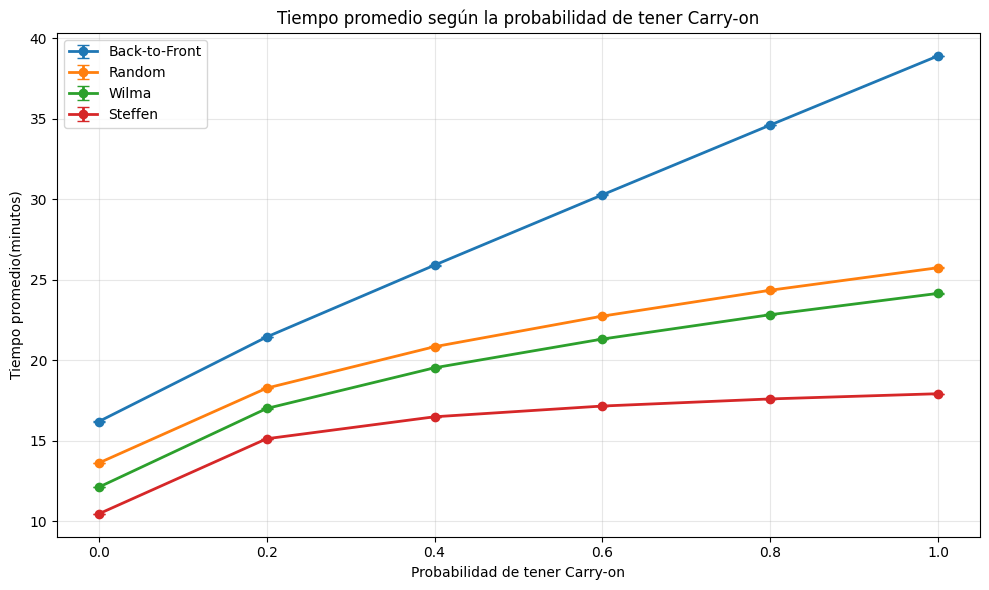

In [ ]:
import pandas as pd
summary_data = []
for politica, data in resultadoscarry.items():
    summary_data.append({
        'Politica': politica,
        'Media': data['media(minutos)'],
        'Desvío Estándar': data['desvio(minutos)'],
        'Error Estándar': data['error_estandar(minutos)']
    })

df_summary = pd.DataFrame(summary_data)
display(df_summary)
import matplotlib.pyplot as plt
import re

# Diccionario para organizar los datos por política
datos = {}

for clave, valores in resultadoscarry.items():
    match = re.match(r"(.+) proba=([0-9.]+)", clave)

    if match:
        politica = match.group(1)
        p_valor = float(match.group(2))

        if politica not in datos:
            datos[politica] = {
                "proba": [],
                "media": [],
                "error": []
            }

        datos[politica]["proba"].append(p_valor)
        datos[politica]["media"].append(valores["media(minutos)"])
        datos[politica]["error"].append(valores["error_estandar(minutos)"])
# Graficar
plt.figure(figsize=(10, 6))

for politica, valores in datos.items():
    # Ordenar por probabilidad por seguridad
    orden = sorted(range(len(valores["proba"])),
                   key=lambda i: valores["proba"][i])

    x = [valores["proba"][i] for i in orden]
    y = [valores["media"][i] for i in orden]
    error = [valores["error"][i] for i in orden]

    plt.errorbar(
        x,
        y,
        yerr=error,
        marker="o",
        capsize=4,
        linewidth=2,
        label=politica
    )

plt.xlabel("Probabilidad de tener Carry-on")
plt.ylabel("Tiempo promedio(minutos)")
plt.title("Tiempo promedio según la probabilidad de tener Carry-on")
plt.xticks(proba)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
tabla_extremos = []
for politica, valores in datos.items():
    idx_p0 = valores["proba"].index(min(valores["proba"]))
    idx_p1 = valores["proba"].index(max(valores["proba"]))
    tabla_extremos.append({
        "politica": politica,
        "media p=0(minutos)": valores["media"][idx_p0],
        "media p=1(minutos)": valores["media"][idx_p1],
    })

df_extremos = pd.DataFrame(tabla_extremos)
display(df_extremos)

,politica,media p=0(minutos),media p=1(minutos)
0,Back-to-Front,16.188406,38.918928
1,Random,13.611261,25.749300
2,Wilma,12.108833,24.153356
3,Steffen,10.450000,17.916667


In [ ]:
costo_demora_30min = costo_minuto * 30
print("costo de una demora de 30 minutos:", costo_demora_30min)

costo de una demora de 30 minutos: 2952.2999999999997


In [ ]:
def run_simulations_ocupacion(funcion_orden, proba, ocupacion, num_simulations=500):
    tiempos = []
    for i in range(num_simulations):
        avion = Avion(proba)
        orden_completo = funcion_orden(avion)
        cantidad_a_bordear = round(len(orden_completo) * ocupacion)
        pasajeros_random = list(avion.pasajeros)
        random.shuffle(pasajeros_random)
        pasajeros_que_suben = set(pasajeros_random[:cantidad_a_bordear])
        orden = [p for p in orden_completo if p in pasajeros_que_suben]
        tiempo = simulacion(avion, orden)
        tiempos.append(tiempo)

    media = np.mean(tiempos)
    desvio = np.std(tiempos, ddof=1)
    error_estandar = desvio / np.sqrt(len(tiempos))
    return tiempos, media, desvio, error_estandar

politicas = [("Back-to-Front", Backtofront), ("Random", orden_random), ("Wilma", orden_wilma), ("Steffen", orden_steffen)]
ocupaciones = [0.9, 0.8, 0.7]
asientos_totales = filas * len(lados)

filas_resultado = []
for nombre_politica, funcion in politicas:
    _, media_full, _, _ = run_simulations_ocupacion(funcion, p_carryon, 1.0)
    filas_resultado.append({
        "politica": nombre_politica,
        "ocupacion": 1.0,
        "asientos_vacios": 0,
        "tiempo_medio(minutos)": media_full/60,
        "ahorro_operativo_usd": 0.0,
        "ingreso_perdido_usd": 0.0,
        "conviene_dejar_vacios": False,
    })
    for ocupacion in ocupaciones:
        _, media, desvio, error_estandar = run_simulations_ocupacion(funcion, p_carryon, ocupacion)
        asientos_vacios = round(asientos_totales * (1 - ocupacion))
        ahorro_segundos = media_full - media
        ahorro_usd = (ahorro_segundos / 60) * costo_minuto
        ingreso_perdido = asientos_vacios * tarifa
        filas_resultado.append({
            "politica": nombre_politica,
            "ocupacion": ocupacion,
            "asientos_vacios": asientos_vacios,
            "tiempo_medio(minutos)": media/60,
            "ahorro_operativo_usd": ahorro_usd,
            "ingreso_perdido_usd": ingreso_perdido,
            "conviene_dejar_vacios": ahorro_usd > ingreso_perdido,
        })

df_costos = pd.DataFrame(filas_resultado)
display(df_costos)

,politica,ocupacion,asientos_vacios,tiempo_medio(minutos),ahorro_operativo_usd,ingreso_perdido_usd,conviene_dejar_vacios
0,Back-to-Front,1.0,0,33.465833,0.000000,0.0,False
1,Back-to-Front,0.9,10,29.361300,403.927125,3870.0,False
2,Back-to-Front,0.8,20,25.170233,816.369996,7740.0,False
3,Back-to-Front,0.7,30,21.212467,1205.853814,11610.0,False
4,Random,1.0,0,23.872433,0.000000,0.0,False
5,Random,0.9,10,21.723933,211.433885,3870.0,False
6,Random,0.8,20,19.455300,434.690091,7740.0,False
7,Random,0.7,30,17.102333,666.245541,11610.0,False
8,Wilma,1.0,0,22.444533,0.000000,0.0,False
9,Wilma,0.9,10,20.495033,191.850295,3870.0,False


In [ ]:
#bonus point
#supuesto para el trade-off
vel_habla = 4.5
vel_caminata = 0.75
dist_fila = [5, 10, 15, 20]  #esto vamos variando ya que no seimpre estamos a la misma dist que la puerta de embarque
silabas_nombre = 6 #buscamos y es la media de los nombres y apellidos en español
sueldo = 18.0 #sueldo por hora
#Calculos
anuncio_nombre = silabas_nombre/vel_habla

filas_tabla = []
for dist in dist_fila:
  tiempo_caminata = dist / vel_caminata
  tiempo_pasajero = anuncio_nombre + tiempo_caminata
  fila_stf = 100 * tiempo_pasajero
  print(fila_stf)

  tiempo_stf = np.mean(resultados['Steffen']['tiempos']) + fila_stf   #se le suma a la media del llenado de avion el timpo de armar la fila
  tiempo_random = np.mean(resultados['Random']['tiempos'])

  if tiempo_stf < tiempo_random:
        conviene_steffen = 'Si'
  else:
        conviene_steffen = 'No'

  #aca veo cuanto costaria
  costo_demora_steffen = (tiempo_stf / 60) * costo_minuto
  costo_demora_random = (tiempo_random / 60) * costo_minuto

  costo_stf = (fila_stf / 3600) * sueldo # esto es solo en steffen se le agrega el costo de empleada que organiza

  costo_total_stf = costo_demora_steffen + costo_stf
  costo_total_random = costo_demora_random + 0

  fila_resultado = {
        'Distancia(me)': dist,
        'Armado de fila Steffen(mi)': round(fila_stf/60, 1),
        'Tiempo final Steffen(mi)': round(tiempo_stf/60, 1),
        'Tiempo final Random(mi)': round(tiempo_random/60, 1),
        'Costo Steffen(USD)': round(costo_total_stf, 2),
        'Costo Random(USD)': round(costo_total_random, 2),
        'Conviene Steffen?': conviene_steffen,
    }
  filas_tabla.append(fila_resultado)

# convertimos la lista de resultados en una tabla para verla ordenada
df_sensibilidad = pd.DataFrame(filas_tabla)
display(df_sensibilidad)



800.0
1466.6666666666667
2133.333333333333
2800.0


,Distancia(me),Armado de fila Steffen(mi),Tiempo final Steffen(mi),Tiempo final Random(mi),Costo Steffen(USD),Costo Random(USD),Conviene Steffen?
0,5,13.3,30.8,24.0,3038.26,2357.18,No
1,10,24.4,41.9,24.0,4135.04,2357.18,No
2,15,35.6,53.1,24.0,5231.82,2357.18,No
3,20,46.7,64.2,24.0,6328.60,2357.18,No
